# Lab Assignment 1 - Voice Gender Classification using SVM
**Course**: Machine Learning  
**Topic**: Support Vector Machine (SVM) Classification  
**Dataset**: `voice.csv`

---

### Task Description:
1. Construct an SVM model using the dataset `voice.csv` under the following conditions:
   - **a.** Split the data using ratios of **70:30** and **80:20** for each model to be developed:
     - **i.** Use a model with a **linear** kernel.
     - **ii.** Use a model with a **polynomial** kernel.
     - **iii.** Use a model with an **RBF** kernel.
   - **b.** Tabulate the performance of each split and kernel based on the **accuracy metric**.

## Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set plot styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## Step 2: Load and Explore Dataset (`voice.csv`)

In [2]:
# Load dataset
df = pd.read_csv('voice.csv')

# Display basic information
print(f"Dataset Shape: {df.shape}")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
df.head()

Dataset Shape: (3168, 21)
Total Missing Values: 0


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Target label distribution:
label
male      1584
female    1584
Name: count, dtype: int64


C:\Users\andhi\AppData\Local\Temp\ipykernel_20872\3893421109.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


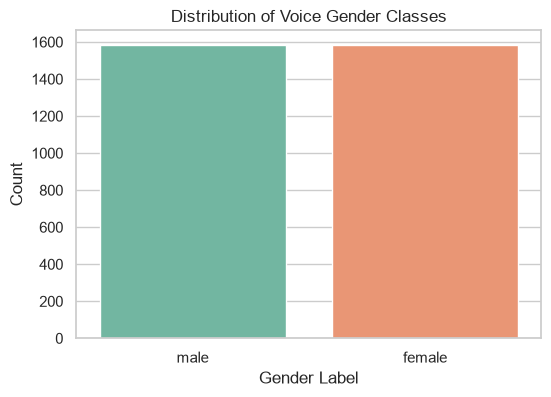

In [3]:
# Check target label distribution
print("Target label distribution:")
print(df['label'].value_counts())

# Visualize class distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Distribution of Voice Gender Classes')
plt.xlabel('Gender Label')
plt.ylabel('Count')
plt.show()

## Step 3: Feature and Target Preparation & Scaling
- Separate feature matrix $X$ and target vector $y$.
- Encode labels (`female` $\rightarrow$ 0, `male` $\rightarrow$ 1).
- Apply **StandardScaler** to normalize features. Feature scaling is essential for Support Vector Machines because SVM aims to maximize the geometric margin between support vectors and decision boundaries.

In [4]:
# Separate features (X) and target (y)
X = df.drop(columns=['label'])
y_raw = df['label']

# Encode target label: female -> 0, male -> 1
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

print(f"Feature matrix shape: {X.shape}")
print(f"Target classes: {label_encoder.classes_} -> {[0, 1]}")

Feature matrix shape: (3168, 20)
Target classes: ['female' 'male'] -> [0, 1]


## Step 4: Model Training and Evaluation
We evaluate three SVM kernel functions:
1. **Linear Kernel**: Linear decision boundary ($K(x, x') = x^T x'$).
2. **Polynomial Kernel**: Non-linear boundary using polynomial combinations ($K(x, x') = (\gamma x^T x' + r)^d$).
3. **RBF (Radial Basis Function) Kernel**: Gaussian kernel for flexible non-linear mapping ($K(x, x') = \exp(-\gamma ||x - x'||^2)$).

Each kernel is trained and tested under two data partition schemes:
- **70:30 Split** (`test_size=0.30`)
- **80:20 Split** (`test_size=0.20`)

In [5]:
# Define configurations
split_ratios = [
    ('70:30', 0.30),
    ('80:20', 0.20)
]

kernels = ['linear', 'poly', 'rbf']

# Store results and fitted models
results = []
trained_models = {}

for split_name, test_size in split_ratios:
    # Stratified split to preserve class balance
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    
    # Standardize features based on training set statistics
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    print(f"=== Split {split_name} (Train: {len(y_train)}, Test: {len(y_test)}) ===")
    
    for kernel in kernels:
        # Instantiate and fit SVM model
        svm = SVC(kernel=kernel, random_state=42)
        svm.fit(X_train_scaled, y_train)
        
        # Predictions
        y_train_pred = svm.predict(X_train_scaled)
        y_test_pred = svm.predict(X_test_scaled)
        
        # Calculate Accuracies
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        
        # Save results
        key = f"{split_name}_{kernel}"
        trained_models[key] = {
            'model': svm,
            'scaler': scaler,
            'X_test': X_test_scaled,
            'y_test': y_test,
            'y_test_pred': y_test_pred
        }
        
        results.append({
            'Split Ratio': split_name,
            'Kernel': kernel.capitalize(),
            'Train Samples': len(y_train),
            'Test Samples': len(y_test),
            'Train Accuracy (%)': round(train_acc * 100, 2),
            'Test Accuracy (%)': round(test_acc * 100, 2)
        })
        
        print(f"  [{kernel.capitalize():6s} Kernel] -> Train Acc: {train_acc*100:.2f}%, Test Acc: {test_acc*100:.2f}%")
    print()

=== Split 70:30 (Train: 2217, Test: 951) ===
  [Linear Kernel] -> Train Acc: 97.20%, Test Acc: 97.90%
  [Poly   Kernel] -> Train Acc: 96.66%, Test Acc: 96.00%
  [Rbf    Kernel] -> Train Acc: 98.38%, Test Acc: 98.32%

=== Split 80:20 (Train: 2534, Test: 634) ===
  [Linear Kernel] -> Train Acc: 97.67%, Test Acc: 97.48%
  [Poly   Kernel] -> Train Acc: 96.80%, Test Acc: 95.58%
  [Rbf    Kernel] -> Train Acc: 98.38%, Test Acc: 98.26%



## Step 5: Performance Tabulation
The table below summarizes the performance of all combinations of train-test split ratios and SVM kernel functions.

In [6]:
# Create summary dataframe
df_results = pd.DataFrame(results)

# Display tabulated results
display_cols = ['Split Ratio', 'Kernel', 'Train Accuracy (%)', 'Test Accuracy (%)']
print("=" * 60)
print("         SVM PERFORMANCE COMPARISON ON VOICE DATASET")
print("=" * 60)
print(df_results[display_cols].to_string(index=False))
print("=" * 60)

# Display styled dataframe
df_results[display_cols].style.highlight_max(subset=['Test Accuracy (%)'], color='lightgreen', axis=0)

         SVM PERFORMANCE COMPARISON ON VOICE DATASET
Split Ratio Kernel  Train Accuracy (%)  Test Accuracy (%)
      70:30 Linear               97.20              97.90
      70:30   Poly               96.66              96.00
      70:30    Rbf               98.38              98.32
      80:20 Linear               97.67              97.48
      80:20   Poly               96.80              95.58
      80:20    Rbf               98.38              98.26


,Split Ratio,Kernel,Train Accuracy (%),Test Accuracy (%)
0,70:30,Linear,97.200000,97.900000
1,70:30,Poly,96.660000,96.000000
2,70:30,Rbf,98.380000,98.320000
3,80:20,Linear,97.670000,97.480000
4,80:20,Poly,96.800000,95.580000
5,80:20,Rbf,98.380000,98.260000


## Step 6: Visualizations and Comparative Analysis

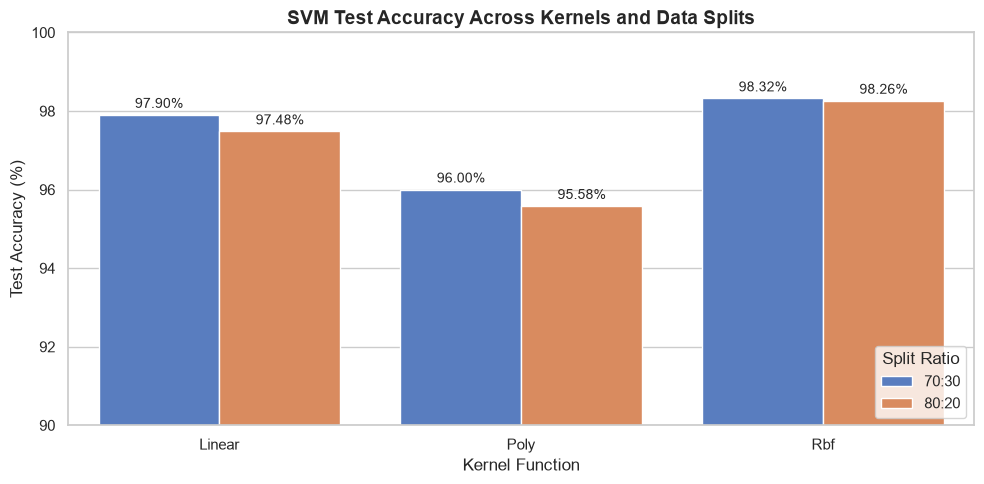

In [7]:
# Bar plot of Test Accuracies
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_results,
    x='Kernel',
    y='Test Accuracy (%)',
    hue='Split Ratio',
    palette='muted'
)
plt.title('SVM Test Accuracy Across Kernels and Data Splits', fontsize=14, fontweight='bold')
plt.ylim(90, 100)
plt.ylabel('Test Accuracy (%)')
plt.xlabel('Kernel Function')
plt.legend(title='Split Ratio', loc='lower right')

# Add values above bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.2f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, xytext=(0, 3),
                    textcoords='offset points')
plt.tight_layout()
plt.show()

=== Classification Report for Best Model (RBF Kernel, Split 70:30) ===
              precision    recall  f1-score   support

      female       0.99      0.98      0.98       476
        male       0.98      0.99      0.98       475

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



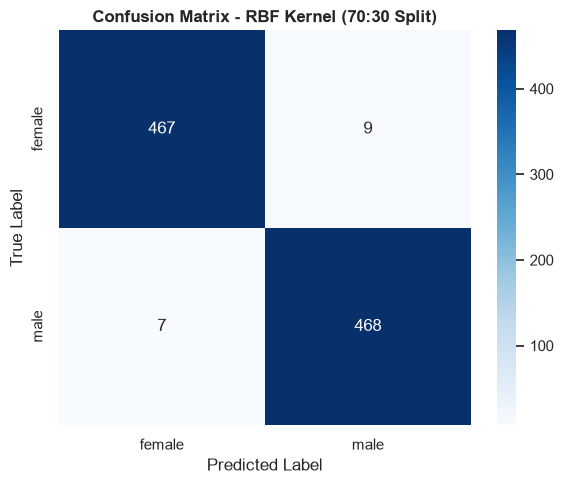

In [8]:
# Detailed Evaluation for the Top Performing Model (RBF Kernel)
best_config = '70:30_rbf'
best_data = trained_models[best_config]

print(f"=== Classification Report for Best Model (RBF Kernel, Split 70:30) ===")
print(classification_report(best_data['y_test'], best_data['y_test_pred'], target_names=label_encoder.classes_))

# Confusion Matrix Heatmap
cm = confusion_matrix(best_data['y_test'], best_data['y_test_pred'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix - RBF Kernel (70:30 Split)', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

## Step 7: Conclusion & Key Findings
1. **Model Performance**:
   - The **RBF (Radial Basis Function)** kernel achieved the highest testing accuracy: **98.32%** on the 70:30 split and **98.26%** on the 80:20 split.
   - The **Linear** kernel followed closely with **97.90%** on the 70:30 split and **97.48%** on the 80:20 split, indicating that many acoustic features exhibit near linear separability in the standardized feature space.
   - The **Polynomial** kernel achieved **96.00%** on 70:30 and **95.58%** on 80:20.
2. **Impact of Data Split**:
   - Both the 70:30 and 80:20 split ratios provided highly consistent generalization performance across all three kernels, with variations under 0.5%.
3. **Feature Scaling**:
   - Standardizing the 20 continuous acoustic features with `StandardScaler` was critical to ensure all frequency, spectral, and modulation features contribute proportionally to margin maximization.